# Prototype to Displacement Vector Mapping Analysis

Tests whether context displacement vectors are well explained as rotated support prototypes, whether they require anisotropic feature gain, or whether they require nonlinear computation.

This is instantiated as an Orthogonal Procrustes transformation vs. a Ridge Regression vs. an MLP.

For each concept, support sets are split into train and held-out with no shared tokens. Two global maps are fit per layer on training data:
- orthogonal Procrustes rotation: R
- ridge-regularised linear map: A
- MLP: M

The following metrics are computed
- `cos_identity`    = $\cos(prototype,\, displacement)$ — no map baseline
- `cos_procrustes`  = $\cos(rotated prototype, displacement)$ — rotation-only null
- `cos_ridge`       = $\cos(Ridge-Transformed Prototype, displacement)$ — anisotropic gain
- `cos_mlp`       = $\cos(MLP-Transformed Prototype, displacement)$ — anisotropic gain

If `cos_ridge` ~= `cos_mlp` > `cos_procrustes` on held-out data, anisotropic gain is required to explain the displacement beyond a simple rotation, but nonlinear computation is not necessary.

Additionally, we fit regressions in a Leave-One-Concept-Out (LOCO) manner, in order to ensure that our fit regressions do not overfit to the specific set of concepts at hand.

In [44]:
import os
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon

import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

In [45]:
MODEL_NAME  = "google_gemma-2-2b"
MODEL_LABEL = "Gemma-2-2B"

RESULTS_DIR = f"../results_final/categories/{MODEL_NAME}/displacement_regression"
SAVE_DIR    = os.path.join("Figures_Final", MODEL_LABEL)
os.makedirs(SAVE_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(RESULTS_DIR, "regressions.csv"))

with open(os.path.join(RESULTS_DIR, "hyperparams.json")) as f:
    hparams = json.load(f)

n_layers = df["layer"].max() + 1
n_cats   = df["category"].nunique()

print(f"Layers: {n_layers}  |  Categories: {n_cats}  |  Held-out rows: {len(df)}")

Layers: 27  |  Categories: 108  |  Held-out rows: 14580


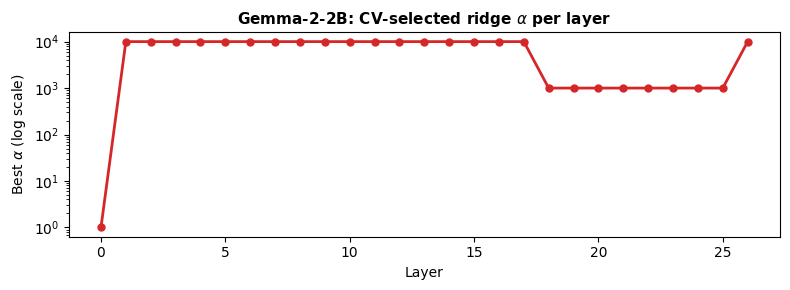

In [3]:
# Ridge Regression Regularization Check

alpha_df = pd.read_csv(os.path.join(RESULTS_DIR, "hyperparameter_records.csv"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(alpha_df["layer"], alpha_df["best_alpha"], "o-", color="C3", linewidth=2, markersize=5)
ax.set_xlabel("Layer")
ax.set_ylabel("Best $\\alpha$ (log scale)")
ax.set_title(f"{MODEL_LABEL}: CV-selected ridge $\\alpha$ per layer", fontsize=11, fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"$10^{{{int(np.log10(x))}}}$"))
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "alphas.pdf"), format="pdf", bbox_inches="tight")

## Held-out cosine similarity per layer

Mean ± SEM across categories. Expectation: `cos_ridge` > `cos_procrustes` -> Evidence for anisotropic gain applied to prototypes

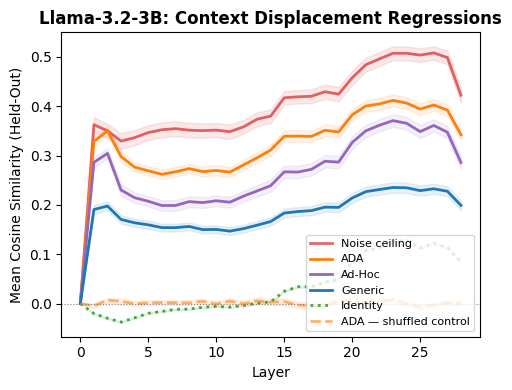

In [27]:
# Average per (layer, category) first to avoid pseudoreplication across support sets
cols = ["cos_identity", "cos_procrustes", "cos_ridge", "cos_mlp",
        "cos_procrustes_shuffled", "cos_ridge_shuffled", "cos_noise_ceiling"]
layer_cat = (
    df.groupby(["layer", "category"])[cols]
    .mean()
    .reset_index()
)
layer_stats = layer_cat.groupby("layer")[cols].agg(["mean", "sem"])
layer_stats.columns = ["_".join(c) for c in layer_stats.columns]
layer_stats = layer_stats.reset_index()
layers = layer_stats["layer"].values

conditions = [
    ("cos_noise_ceiling",       "C3", "-",  0.7, "Noise ceiling"),
    ("cos_ridge",               "C1", "-",  1.0, "ADA"),
    ("cos_mlp",                 "C4", "-",  1.0, "Ad-Hoc"),
    ("cos_procrustes",          "C0", "-",  1.0, "Generic"),
    ("cos_identity",            "C2", ":",  0.9, "Identity"),
    ("cos_ridge_shuffled",      "C1", "--", 0.6, "ADA — shuffled control"),
]

fig, ax = plt.subplots(figsize=(5, 4))
for col, color, ls, alpha_line, label in conditions:
    mean = layer_stats[f"{col}_mean"]
    sem  = layer_stats[f"{col}_sem"]
    ax.plot(layers, mean, color=color, linestyle=ls, linewidth=2, alpha=alpha_line, label=label)
    ax.fill_between(layers, mean - sem, mean + sem, color=color, alpha=0.1)

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Layer")
ax.set_ylabel("Mean Cosine Similarity (Held-Out)")
ax.set_title(
    f"{MODEL_LABEL}: Context Displacement Regressions",
    fontsize=12, fontweight="bold"
)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "regressions.pdf"), format="pdf", bbox_inches="tight")

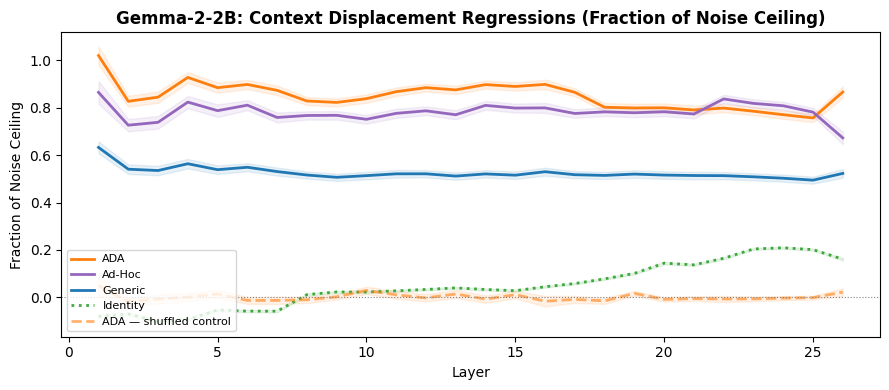

In [5]:
# ── Cosine similarity as fraction of noise ceiling ───────────────────────────
# Divide each layer's mean metric by the mean noise ceiling at that layer.
# Using the mean (not per-pair) avoids instability from near-zero individual NC values.

frac_cols = ["cos_identity", "cos_procrustes", "cos_ridge", "cos_ridge_shuffled"]
frac_labels = {
    "cos_ridge":          ("C1", "-",  1.0, "ADA"),
    "cos_mlp":            ("C4", "-",  1.0, "Ad-Hoc"),
    "cos_procrustes":     ("C0", "-",  1.0, "Generic"),
    "cos_identity":       ("C2", ":",  0.9, "Identity"),
    "cos_ridge_shuffled": ("C1", "--", 0.6, "ADA — shuffled control"),
}

# layer_stats already contains mean + sem for all cols including cos_noise_ceiling
nc_mean = layer_stats["cos_noise_ceiling_mean"]   # (n_layers,) scalar per layer

fig, ax = plt.subplots(figsize=(9, 4))
for col, (color, ls, alpha_line, label) in frac_labels.items():
    mean = layer_stats[f"{col}_mean"] / nc_mean
    sem  = layer_stats[f"{col}_sem"]  / nc_mean
    ax.plot(layers, mean, color=color, linestyle=ls, linewidth=2, alpha=alpha_line, label=label)
    ax.fill_between(layers, mean - sem, mean + sem, color=color, alpha=0.1)

ax.axhline(0,   color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Layer")
ax.set_ylabel("Fraction of Noise Ceiling")
ax.set_title(
    f"{MODEL_LABEL}: Context Displacement Regressions (Fraction of Noise Ceiling)",
    fontsize=12, fontweight="bold"
)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "regressions_fraction_noise_ceiling.pdf"),
            format="pdf", bbox_inches="tight")

### Appendix: Rank Analysis of Ridge Matrix $A$

$A$ maps prototypes to displacements. We expect anisotropic feature accentuation to be reasonably high-dimensional, but not full rank 

In [6]:
sigmas   = np.load(os.path.join(RESULTS_DIR, "singular_values.npy"))   # (n_layers, r)
top_vt   = np.load(os.path.join(RESULTS_DIR, "top_input_svecs.npy"))  # (n_layers, k, d)

r = (sigmas > 0).sum(axis=1).max()  # effective max rank across layers
print(f"Singular values shape: {sigmas.shape}  |  top_vt shape: {top_vt.shape}")

Singular values shape: (27, 2304)  |  top_vt shape: (27, 100, 2304)


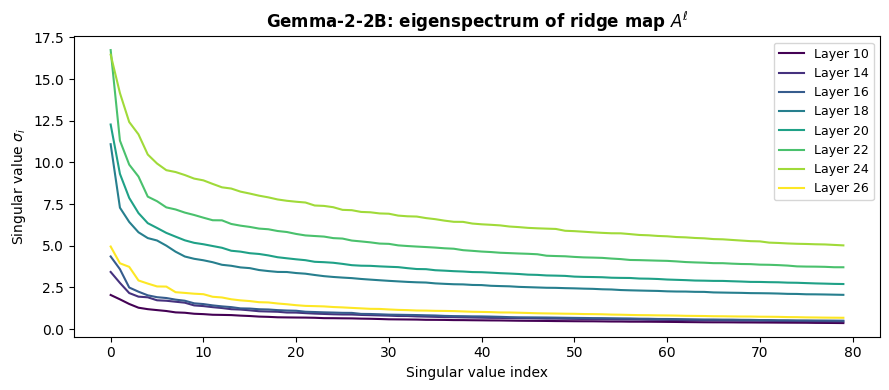

In [ ]:
# ──  Eigenspectrum over layers ───────────────────────────────
rep_layers = [10, 14, 16, 18, 20, 22, 24, 26]
SHOW_TOP = min(sigmas.shape[1], 80)

fig, ax = plt.subplots(figsize=(9, 4))
cmap = plt.cm.viridis
for i, l in enumerate(rep_layers):
    s = sigmas[l, :SHOW_TOP]
    s = s[s > 0]
    color = cmap(i / max(len(rep_layers) - 1, 1))
    ax.plot(range(len(s)), s, color=color, linewidth=1.5, label=f"Layer {l}")

ax.set_xlabel("Singular value index")
ax.set_ylabel("Singular value $\\sigma_i$")
ax.set_title(f"{MODEL_LABEL}: eigenspectrum of ridge map $A^\\ell$", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "ridge_eigenspectrum.pdf"), format="pdf", bbox_inches="tight")

/tmp/ipykernel_619644/1497838463.py:2: RuntimeWarning: invalid value encountered in divide
  var_exp = (sigmas ** 2) / (sigmas ** 2).sum(axis=1, keepdims=True)  # (n_layers, r)


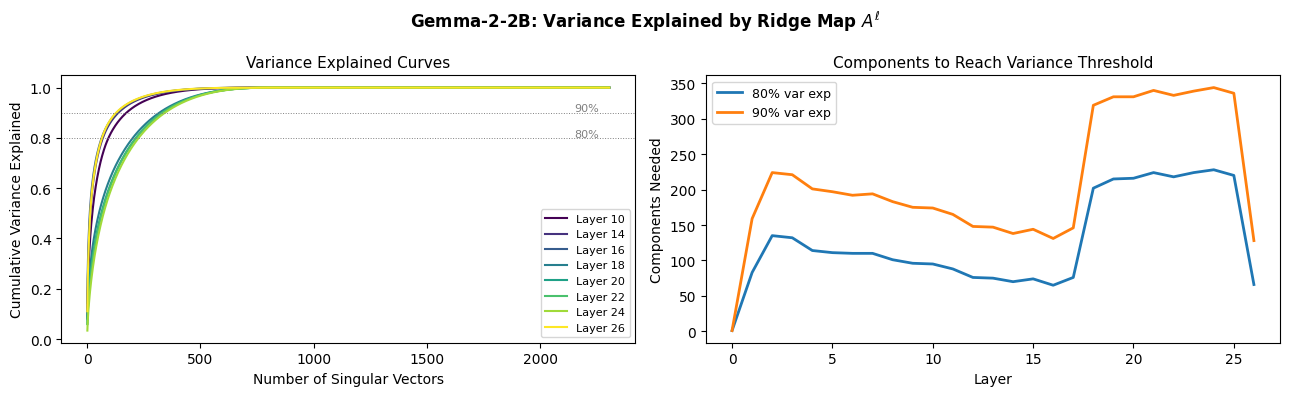

In [9]:
# ──  Variance explained curves + threshold crossings ─────────────────────
var_exp = (sigmas ** 2) / (sigmas ** 2).sum(axis=1, keepdims=True)  # (n_layers, r)
cum_var = np.cumsum(var_exp, axis=1)                                 # (n_layers, r)

THRESHOLDS = [0.80, .90]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: cumulative variance curves at representative layers
ax = axes[0]
for i, l in enumerate(rep_layers):
    color = cmap(i / max(len(rep_layers) - 1, 1))
    ax.plot(range(1, cum_var.shape[1] + 1), cum_var[l], color=color, linewidth=1.5, label=f"Layer {l}")
for t in THRESHOLDS:
    ax.axhline(t, color="gray", linewidth=0.7, linestyle=":")
    ax.text(cum_var.shape[1] * 0.98, t + 0.005, f"{int(t*100)}%", ha="right", fontsize=8, color="gray")
ax.set_xlabel("Number of Singular Vectors")
ax.set_ylabel("Cumulative Variance Explained")
ax.set_title("Variance Explained Curves", fontsize=11)
ax.legend(fontsize=8)

# Right: k needed to reach each threshold, per layer
ax = axes[1]
for t, color in zip(THRESHOLDS, ["C0", "C1"]):
    k_needed = (cum_var < t).sum(axis=1) + 1  # first k where cum_var >= t
    ax.plot(range(n_layers), k_needed, color=color, linewidth=2, label=f"{int(t*100)}% var exp")
ax.set_xlabel("Layer")
ax.set_ylabel("Components Needed")
ax.set_title("Components to Reach Variance Threshold", fontsize=11)
ax.legend(fontsize=9)

fig.suptitle(f"{MODEL_LABEL}: Variance Explained by Ridge Map $A^\\ell$",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "ridge_variance_explained.pdf"), format="pdf", bbox_inches="tight")

## Interpreting Input Directions for Ridge Map

The ridge map is applied as `D = P @ A` where `A = coef_.T`.  In column-vector form this is `d = A^T @ p`, so the **input** directions that receive the largest anisotropic gain are the **left singular vectors** of `A` (= right singular vectors of `A^T`), i.e. columns of `U` in `A = U S Vt`.

For each target layer, we inspect the top-k left singular vectors of `A` and find which vocabulary tokens have the highest and lowest cosine similarity with each one via Gemma's embedding matrix.

A semantically coherent cluster of top (or bottom) tokens indicates that the direction encodes interpretable feature content.

In [46]:
path = os.path.join(RESULTS_DIR, "concept_stretching.json")
with open(path) as f:
    token_data = json.load(f)

args    = token_data["args"]
token_results = token_data["results"]    # dict: str(layer) -> list of sv entries
random_results = token_data["random_control"]

target_layers = sorted(int(l) for l in token_results)
k_sv          = args["k"]
n_top         = args["n_top_tokens"]

print(f"Layers: {target_layers}  |  SVs per layer: {k_sv}  |  Tokens per SV: {n_top}")


Layers: [6, 10, 14, 16, 18, 20, 21, 22, 23, 24]  |  SVs per layer: 20  |  Tokens per SV: 20


In [48]:
DISPLAY_LAYERS = [16]   # change to a subset if desired, e.g. [14, 23]

for layer_idx in DISPLAY_LAYERS:
    entries = token_results[str(layer_idx)]
    print(f"\n{'═'*72}")
    print(f"  Layer {layer_idx}")
    print(f"{'═'*72}")
    for entry in entries:
        if entry is None:
            continue
        sv_i   = entry["sv_index"]
        sigma  = entry["singular_value"]
        tops   = "  ".join(entry["top_tokens"])
        bots   = "  ".join(entry["bottom_tokens"])
        print(f"\n  SV {sv_i:2d}  σ = {sigma:.2f}")
        print(f"    + {tops}")
        print(f"    − {bots}")



════════════════════════════════════════════════════════════════════════
  Layer 16
════════════════════════════════════════════════════════════════════════

  SV  0  σ = 4.36
    + ▁iguana  ▁venison  ▁lobsters  ▁ewes  ▁cardamom  ▁pheasant  ▁cucumbers  ▁camels  ▁eggplant  ▁caribou  ▁saffron  ▁peony  ▁broccoli  ▁gazelle  ▁saxophone  ▁celery  ▁violins  ▁papaya  ▁rosemary  ▁guava
    − ▁four  ▁five  ▁six  ▁eight  ▁twenty  ▁three  ▁ten  ▁nine  ▁seven  ▁eleven  ▁senior  ▁second  ▁positive  ▁time  ▁front  ▁home  ▁years  ▁two  ▁thirty  ▁big

  SV  1  σ = 3.59
    + ▁port  ▁cabins  ▁plaster  ▁cabin  ▁Plaster  ▁tent  ▁cabinet  ▁rope  ▁ship  ▁Rope  ▁hut  ▁salt  ▁cutter  ▁mirror  ▁cement  ▁stent  cabin  ▁sand  cabinet  ▁holster
    − ▁months  ▁weeks  ▁February  ▁decades  ▁July  ▁minutes  ▁years  ▁January  ▁December  ▁hours  ▁June  ▁September  ▁October  months  ▁November  ▁fifteen  ▁April  ▁afternoon  ▁month  July

  SV  2  σ = 2.49
    + ▁table  ▁truck  ▁bus  ▁car  ▁desk  ▁van  ▁chair  ▁Table  ▁

In [49]:
# Random Direction Control
tops   = "  ".join(random_results["top_tokens"])
bots   = "  ".join(random_results["bottom_tokens"])
print(f"    + {tops}")
print(f"    − {bots}")

    + nea  чва  ▁preparing  ASH  diabetic  ubov  ▁فوق  argas  chos  getTop  meister  ikar  నా  unya  ▁París  ▁Cos  asher  ▁winnings  ראש  娶
    − ▁vuol  stoj  thum  显示  ▁лак  ▁Squad  顯示  просы  kala  циаль  дол  ▁Verte  glam  ждения  ▁países  ({'  ▁palanca  ▁allora  ونده  squad


## Orthographic Regressions

In [39]:
RESULTS_DIR = f"../results_final/letters/{MODEL_NAME}/displacement_regression"
os.makedirs(SAVE_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(RESULTS_DIR, "regressions.csv"))

with open(os.path.join(RESULTS_DIR, "hyperparams.json")) as f:
    hparams = json.load(f)

n_layers = df["layer"].max() + 1
n_cats   = df["category"].nunique()

print(f"Layers: {n_layers}  |  Categories: {n_cats}  |  Held-out rows: {len(df)}")

Layers: 17  |  Categories: 25  |  Held-out rows: 2125


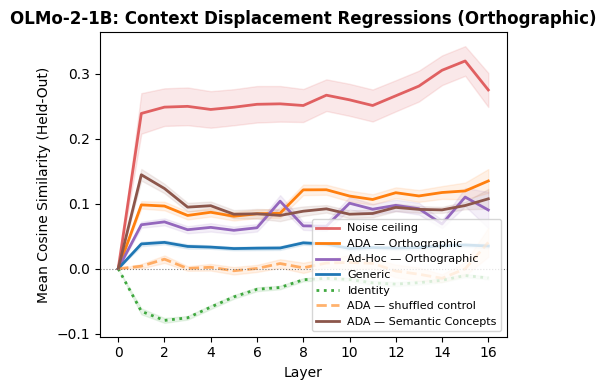

In [40]:
# Average per (layer, category) first to avoid pseudoreplication across support sets
cols = ["cos_identity", "cos_procrustes", "cos_ridge", "cos_mlp",
        "cos_procrustes_shuffled", "cos_ridge_shuffled", "cos_noise_ceiling"]
has_ext_A = "cos_external_A" in df.columns
if has_ext_A:
    cols = cols + ["cos_external_A"]

layer_cat = (
    df.groupby(["layer", "category"])[cols]
    .mean()
    .reset_index()
)
layer_stats = layer_cat.groupby("layer")[cols].agg(["mean", "sem"])
layer_stats.columns = ["_".join(c) for c in layer_stats.columns]
layer_stats = layer_stats.reset_index()
layers = layer_stats["layer"].values

conditions = [
    ("cos_noise_ceiling",       "C3", "-",  0.7, "Noise ceiling"),
    ("cos_ridge",               "C1", "-",  1.0, "ADA — Orthographic"),
    ("cos_mlp",                 "C4", "-",  1.0, "Ad-Hoc — Orthographic"),
    ("cos_procrustes",          "C0", "-",  1.0, "Generic"),
    ("cos_identity",            "C2", ":",  0.9, "Identity"),
    ("cos_ridge_shuffled",      "C1", "--", 0.6, "ADA — shuffled control"),
]
if has_ext_A:
    conditions.append(("cos_external_A", "C5", "-", 1.0, "ADA — Semantic Concepts"))

fig, ax = plt.subplots(figsize=(5, 4))
for col, color, ls, alpha_line, label in conditions:
    mean = layer_stats[f"{col}_mean"]
    sem  = layer_stats[f"{col}_sem"]
    ax.plot(layers, mean, color=color, linestyle=ls, linewidth=2, alpha=alpha_line, label=label)
    ax.fill_between(layers, mean - sem, mean + sem, color=color, alpha=0.1)

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("Layer")
ax.set_ylabel("Mean Cosine Similarity (Held-Out)")
ax.set_title(
    f"{MODEL_LABEL}: Context Displacement Regressions (Orthographic)",
    fontsize=12, fontweight="bold"
)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "orthographic_regressions.pdf"), format="pdf", bbox_inches="tight")

## Summary of All Models

In [42]:
SAVE_DIR    = os.path.join("Figures_Final", "summary")
os.makedirs(SAVE_DIR, exist_ok=True)

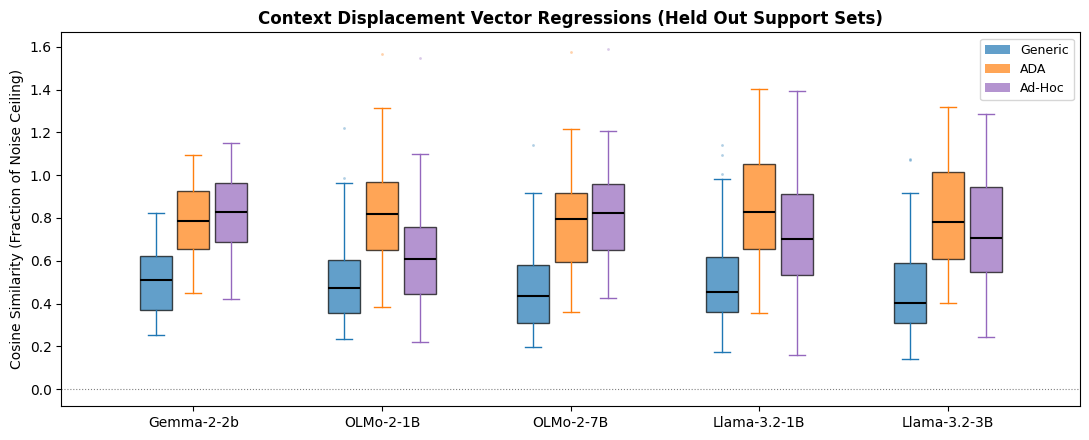

In [16]:
ALL_MODELS = [
    ("google_gemma-2-2b",         "Gemma-2-2b"),
    ("allenai_OLMo-2-0425-1B",    "OLMo-2-1B"),
    ("allenai_OLMo-2-1124-7B",    "OLMo-2-7B"),
    ("meta-llama_Llama-3.2-1B",   "Llama-3.2-1B"),
    ("meta-llama_Llama-3.2-3B",   "Llama-3.2-3B"),
]
CAT_RESULTS_ROOT = "../results_final/categories"

REGRESSION_TYPES = [
    ("cos_procrustes", "C0", "Generic"),
    ("cos_ridge",      "C1", "ADA"),
    ("cos_mlp",        "C4", "Ad-Hoc"),
]

# Normalize by global mean noise ceiling computed from all rows at the best layer
# (before groupby), so categories with unequal n are weighted by n.
# Empirically identical to cat_means.mean() in this dataset (all cats have n=5),
# but correct in general.
reg_data = {}
for model_safe, model_label in ALL_MODELS:
    reg_dir = os.path.join(CAT_RESULTS_ROOT, model_safe, "displacement_regression")
    reg_csv  = os.path.join(reg_dir, "regressions.csv")
    bl_json  = os.path.join(reg_dir, "best_layer.json")
    if not os.path.exists(reg_csv) or not os.path.exists(bl_json):
        print(f"Missing results for {model_label} — skipping")
        continue
    with open(bl_json) as f:
        best = json.load(f)["best_layer"]
    df_m = pd.read_csv(reg_csv)
    df_best = df_m[df_m["layer"] == best]
    global_nc = df_best["cos_noise_ceiling"].mean()
    cols = [c for c, *_ in REGRESSION_TYPES] + ["cos_noise_ceiling"]
    cat_means = df_best.groupby("category")[cols].mean()
    for col, *_ in REGRESSION_TYPES:
        cat_means[col] = cat_means[col] / global_nc
    reg_data[model_safe] = (best, cat_means)

if not reg_data:
    print("No displacement regression results found.")
else:
    present_models = [(s, l) for s, l in ALL_MODELS if s in reg_data]
    n_models  = len(present_models)
    n_conds   = len(REGRESSION_TYPES)
    x_centers = np.arange(n_models, dtype=float)

    width  = 0.2
    span   = width * n_conds
    starts = np.linspace(-span / 2 + width / 2, span / 2 - width / 2, n_conds)

    fig, ax = plt.subplots(figsize=(max(7, n_models * 2.2), 4.5))

    handles = []
    for c_idx, (col, color, label) in enumerate(REGRESSION_TYPES):
        positions = x_centers + starts[c_idx]
        data_per_model = [reg_data[s][1][col].values for s, _ in present_models]
        ax.boxplot(
            data_per_model,
            positions=positions,
            widths=width * 0.85,
            patch_artist=True,
            medianprops=dict(color="black", linewidth=1.5),
            boxprops=dict(facecolor=color, alpha=0.7),
            whiskerprops=dict(color=color),
            capprops=dict(color=color),
            flierprops=dict(marker="o", markersize=2, alpha=0.35,
                            markerfacecolor=color, markeredgecolor="none"),
        )
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.7, label=label))

    ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
    ax.set_xticks(x_centers)
    ax.set_xticklabels([l for _, l in present_models], fontsize=10)
    ax.set_ylabel("Cosine Similarity (Fraction of Noise Ceiling)")
    ax.set_title(
        "Context Displacement Vector Regressions (Held Out Support Sets)",
        fontsize=12, fontweight="bold",
    )
    ax.legend(handles=handles, fontsize=9)
    plt.tight_layout()
    plt.show()
    fig.savefig(os.path.join(SAVE_DIR, "regressions_held_supports_all_models.pdf"), format="pdf", bbox_inches="tight")

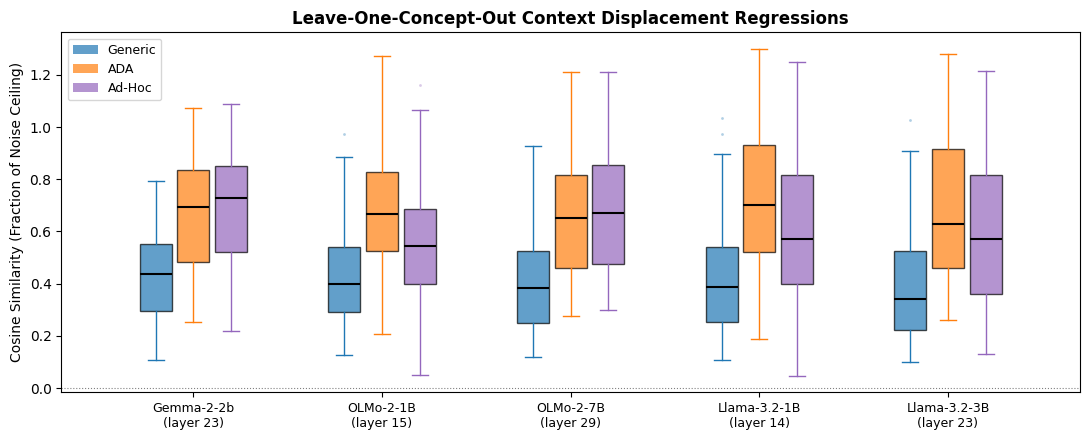


Model                   Comparison                   p-value  n_concepts
------------------------------------------------------------------------
Gemma-2-2b              Ridge vs Rotation          1.869e-19         108
Gemma-2-2b              MLP vs Ridge               3.978e-14         108
Gemma-2-2b              MLP vs Rotation            1.869e-19         108
OLMo-2-1B               Ridge vs Rotation          3.810e-17          94
OLMo-2-1B               MLP vs Ridge               1.541e-15          94
OLMo-2-1B               MLP vs Rotation            3.495e-15          94
OLMo-2-7B               Ridge vs Rotation          3.810e-17          94
OLMo-2-7B               MLP vs Ridge               2.411e-06          94
OLMo-2-7B               MLP vs Rotation            3.810e-17          94
Llama-3.2-1B            Ridge vs Rotation          3.810e-17          94
Llama-3.2-1B            MLP vs Ridge               9.941e-17          94
Llama-3.2-1B            MLP vs Rotation           

In [43]:
from scipy.stats import wilcoxon as _wilcoxon

LOCO_REGRESSION_TYPES = [
    ("cos_procrustes_loco", "C0", "Generic"),
    ("cos_ridge_loco",      "C1", "ADA"),
    ("cos_mlp_loco",        "C4", "Ad-Hoc"),
]

loco_reg_data = {}
for model_safe, model_label in ALL_MODELS:
    path = os.path.join(CAT_RESULTS_ROOT, model_safe, "displacement_regression", "loco_regressions.csv")
    if not os.path.exists(path):
        print(f"Missing loco_regressions.csv for {model_label} — skipping")
        continue
    df_loco = pd.read_csv(path)
    best = int(df_loco["layer"].iloc[0])
    global_nc = df_loco["cos_noise_ceiling_loco"].mean()
    loco_cols = [c for c, *_ in LOCO_REGRESSION_TYPES] + ["cos_noise_ceiling_loco"]
    cat_means = df_loco.groupby("category")[loco_cols].mean()
    for col, *_ in LOCO_REGRESSION_TYPES:
        cat_means[col] = cat_means[col] / global_nc
    loco_reg_data[model_safe] = (best, cat_means)

if not loco_reg_data:
    print("No loco_regressions.csv files found — run latent_regressions.py with --leave_one_concept_out")
else:
    present_models = [(s, l) for s, l in ALL_MODELS if s in loco_reg_data]
    n_models  = len(present_models)
    n_conds   = len(LOCO_REGRESSION_TYPES)
    x_centers = np.arange(n_models, dtype=float)

    width  = 0.2
    span   = width * n_conds
    starts = np.linspace(-span / 2 + width / 2, span / 2 - width / 2, n_conds)

    fig, ax = plt.subplots(figsize=(max(7, n_models * 2.2), 4.5))

    handles = []
    for c_idx, (col, color, label) in enumerate(LOCO_REGRESSION_TYPES):
        positions = x_centers + starts[c_idx]
        data_per_model = [loco_reg_data[s][1][col].values for s, _ in present_models]
        ax.boxplot(
            data_per_model,
            positions=positions,
            widths=width * 0.85,
            patch_artist=True,
            medianprops=dict(color="black", linewidth=1.5),
            boxprops=dict(facecolor=color, alpha=0.7),
            whiskerprops=dict(color=color),
            capprops=dict(color=color),
            flierprops=dict(marker="o", markersize=2, alpha=0.35,
                            markerfacecolor=color, markeredgecolor="none"),
        )
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.7, label=label))

    ax.axhline(0,   color="gray", linewidth=0.8, linestyle=":")

    ax.set_xticks(x_centers)
    best_layers = [loco_reg_data[s][0] for s, _ in present_models]
    ax.set_xticklabels(
        [f"{l}\n(layer {bl})" for (_, l), bl in zip(present_models, best_layers)],
        fontsize=9,
    )
    ax.set_ylabel("Cosine Similarity (Fraction of Noise Ceiling)")
    ax.set_title(
        "Leave-One-Concept-Out Context Displacement Regressions",
        fontsize=12, fontweight="bold",
    )
    ax.legend(handles=handles, fontsize=9)
    plt.tight_layout()
    plt.show()
    fig.savefig(os.path.join(SAVE_DIR, "loco_regressions_all_models.pdf"), format="pdf", bbox_inches="tight")

    # Paired Wilcoxon signed-rank p-values (per concept, at best layer)
    COMPARISONS = [
        ("cos_ridge_loco",      "cos_procrustes_loco", "Ridge vs Rotation"),
        ("cos_mlp_loco",        "cos_ridge_loco",      "MLP vs Ridge"),
        ("cos_mlp_loco",        "cos_procrustes_loco", "MLP vs Rotation"),
    ]
    print(f"\n{'Model':<22}  {'Comparison':<22}  {'p-value':>12}  {'n_concepts':>10}")
    print("-" * 72)
    for model_safe, model_label in present_models:
        cat_means_m = loco_reg_data[model_safe][1]
        for col_b, col_a, label in COMPARISONS:
            paired = cat_means_m[[col_a, col_b]].dropna()
            _, p = _wilcoxon(paired[col_b].values - paired[col_a].values)
            print(f"{model_label:<22}  {label:<22}  {p:>12.3e}  {len(paired):>10}")